In [1]:
%pip install pygad

Note: you may need to restart the kernel to use updated packages.


Problem 1

Initial guess [3, 7], Result: [0.99999564 0.99999127], Value: 1.9028451089739715e-11, Success: True, Iterations: 32, Time: 0.0167 sec
Initial guess [5, 5], Result: [0.99999742 0.99999483], Value: 6.670628346219875e-12, Success: True, Iterations: 54, Time: 0.0272 sec
Initial guess [0, 0], Result: [0.99999467 0.99998932], Value: 2.8439990629105454e-11, Success: True, Iterations: 19, Time: 0.0054 sec
Initial guess [-4, 4], Result: [0.99999558 0.99999114], Value: 1.956595001611041e-11, Success: True, Iterations: 62, Time: 0.0160 sec
Initial guess [4, 0], Result: [0.99999556 0.99999112], Value: 1.9708748423576696e-11, Success: True, Iterations: 67, Time: 0.0240 sec


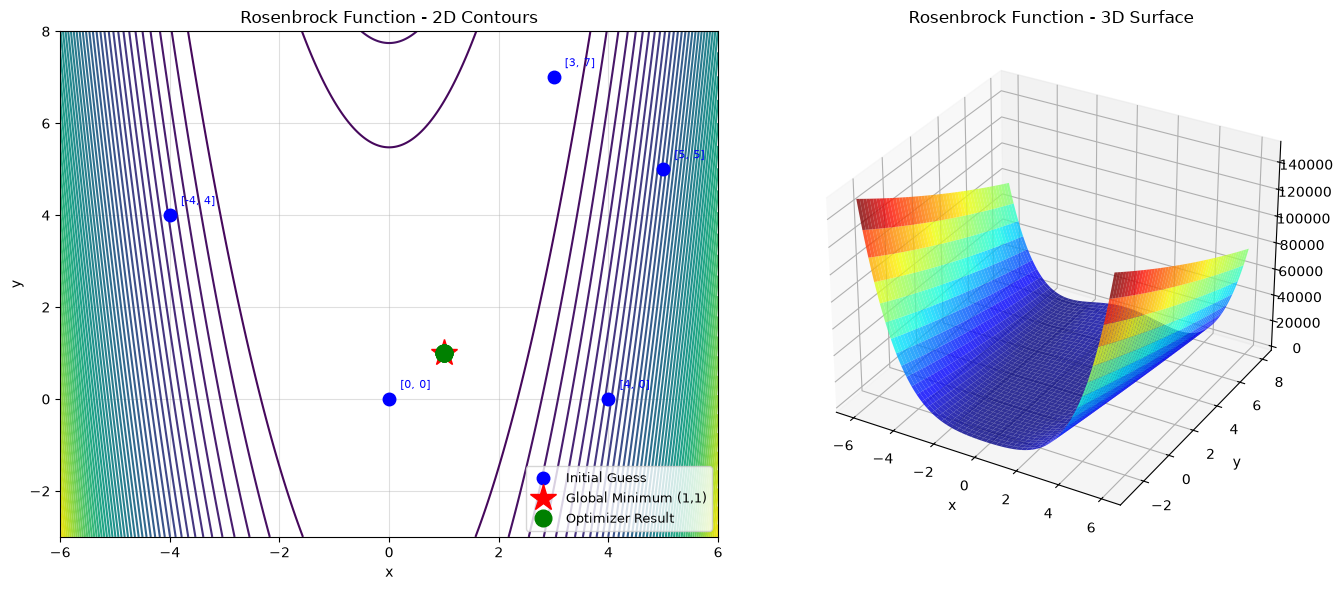

PyGAD initial guess [3, 7], Solution: [1.01281659 1.025074  ], Value: 0.000216601070266909, iterations: 2000, Time: 1.0350 sec
PyGAD initial guess [5, 5], Solution: [1.00192272 1.00399157], Value: 5.725774138187373e-06, iterations: 2000, Time: 0.9992 sec
PyGAD initial guess [0, 0], Solution: [0.98798905 0.97549221], Value: 0.00018397171042453623, iterations: 2000, Time: 1.1776 sec
PyGAD initial guess [-4, 4], Solution: [0.98135259 0.96397903], Value: 0.00043349811981418694, iterations: 2000, Time: 0.9426 sec
PyGAD initial guess [4, 0], Solution: [0.97451959 0.94849896], Value: 0.0007907370941468997, iterations: 2000, Time: 0.9776 sec


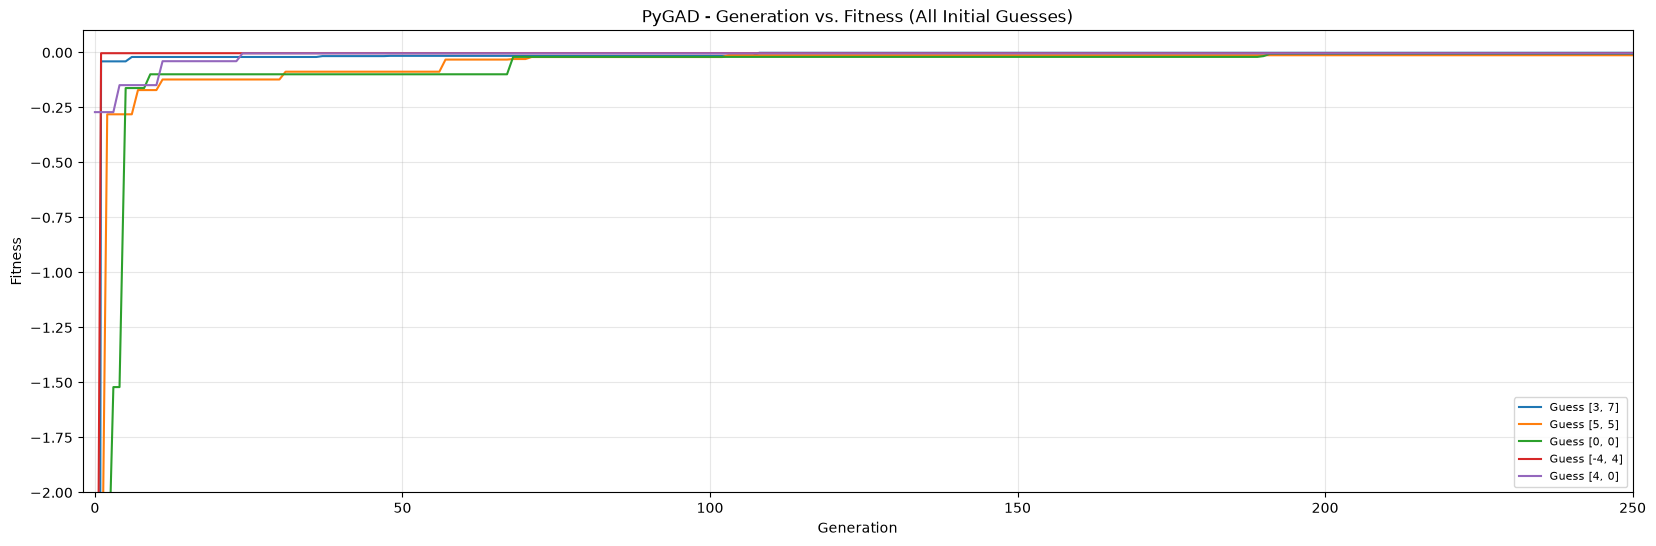

In [15]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# ---------------- Run Scipy Optimization FIRST ----------------
scipy_results = []  # (guess, final_point) pairs

init_guesses = [[3, 7], [5, 5], [0, 0], [-4, 4], [4, 0]]

for guess in init_guesses:
    start_time = time.perf_counter()
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, "
          f"Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")
    scipy_results.append((guess, result.x))

# ---------------- 2D & 3D plots ----------------
x_range = np.linspace(-6, 6, 500)
y_range = np.linspace(-3, 8, 500)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function - 2D Contours")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.grid(True, alpha=0.4)

# plot initial guesses 
for i, (guess, final) in enumerate(scipy_results):
    ax1.plot(guess[0], guess[1], 'o', color='blue', markersize=9, zorder=4,
              label='Initial Guess' if i == 0 else "")
    ax1.annotate(f"[{guess[0]}, {guess[1]}]", (guess[0], guess[1]),
                  textcoords="offset points", xytext=(8, 8),
                  fontsize=8, color='blue')

# global minimum (red star) 
ax1.plot(1, 1, '*', color='red', markersize=20, zorder=4,
          label='Global Minimum (1,1)')

# optimizer results (green) 
for i, (guess, final) in enumerate(scipy_results):
    ax1.plot(final[0], final[1], 'o', color='green', markersize=12, zorder=6,
              label='Optimizer Result' if i == 0 else "")

ax1.legend(fontsize=9, loc='lower right')
ax1.set_xlim(-6, 6)
ax1.set_ylim(-3, 8)

# --- 3D surface ---
ax2 = fig.add_subplot(122, projection='3d')
surf = ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function - 3D Surface")
ax2.set_xlabel("x")
ax2.set_ylabel("y")

plt.tight_layout()
plt.show()

# ---------------- PyGAD Optimization ----------------
# ---------------- PyGAD Optimization ----------------
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution)  # pygad maximizes, so negate

elapsed_time = []
fitness_histories = []  # store (guess, fitness_history) for each run

for guess in init_guesses:
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=2000,
                           sol_per_pop=20,
                           num_genes=2,
                           num_parents_mating=8,
                           fitness_func=fitness_func,
                           init_range_low=-2,
                           init_range_high=2,
                           gene_space={'low': -2, 'high': 2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {rosenbrock(solution)}, "
          f"iterations: {iters}, Time: {elapsed_time:.4f} sec")

    # store this run's fitness-per-generation history
    fitness_histories.append((guess, ga_instance.best_solutions_fitness))

# ---------------- Plot ALL guesses' fitness curves together ----------------
plt.figure(figsize=(20, 6))
for guess, history in fitness_histories:
    plt.plot(history, label=f"Guess {guess}")

plt.title("PyGAD - Generation vs. Fitness (All Initial Guesses)")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)

# zoomed-in view
plt.xlim(-2, 250)
plt.ylim(-2, 0.1)

plt.show()

Ans:

i) We will get the exact solution regardless the initial guess but with some errors. We will get the global minimum for this function.

ii) For pygad, the genetic algorithm also converges to essentially (1, 1) for all guesses, confirming it also finds the global minimum. However, GA needs many more generations (hundreds) and its convergence is less precise (fitness curve shows step-like jumps as better solutions are randomly discovered) compared to BFGS's fast, smooth gradient-driven descent.

iii) Comparison
1. Number of Iterations: BFGS finds the answer in very few steps (around 20–40) because it uses gradient info to move straight toward the minimum. PyGAD needs many more generations (often in the hundreds) since it searches using random trial and error instead of direction.

2. Time Taken: BFGS is very fast, usually just milliseconds per run. PyGAD is slower, often taking a few seconds, because it has to test a whole population of solutions at every generation.

3. Accuracy of Solution: Both methods reach the same global minimum no matter which starting guess is used. But BFGS gives a very precise answer (accurate to many decimal places), while PyGAD's answer is a bit less exact and can vary slightly each time it's run.

4. Overall Comparison: For a smooth function like this, BFGS is faster and more accurate. PyGAD is more useful when gradients aren't available or the function is messy/noisy, but for this problem, BFGS is clearly the better choice.

PART 1: scipy.optimize (BFGS)
Guess [0, 4] -> Result: [-0.999999, -0.000002], f(x)=5.77e-12, Success=True, Iter=17, Time=0.0043s
Guess [-5, 6] -> Result: [-1.000000, 0.000001], f(x)=1.92e-12, Success=True, Iter=27, Time=0.0045s
Guess [-1, 4] -> Result: [-1.000000, -0.000000], f(x)=2.47e-13, Success=True, Iter=16, Time=0.0021s
Guess [2, 2] -> Result: [-1.000000, 0.000000], f(x)=2.72e-14, Success=True, Iter=15, Time=0.0025s
Guess [-3, 3] -> Result: [-0.999999, -0.000001], f(x)=3.11e-12, Success=True, Iter=15, Time=0.0018s
Guess [4, 0] -> Result: [-1.000000, -0.000000], f(x)=1.09e-15, Success=True, Iter=11, Time=0.0018s


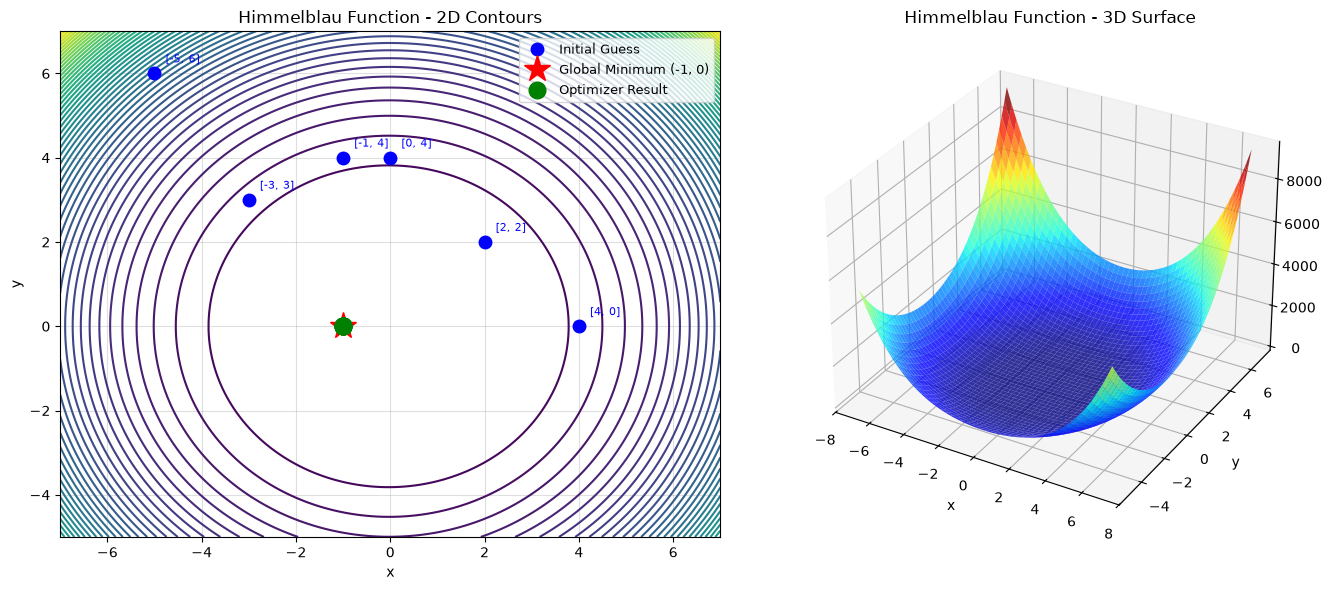


PART 2: PyGAD (Genetic Algorithm)
Guess [0, 4] -> Solution: [-1.000688, -0.002322], f(x)=7.78e-06, Iter=300, Time=0.1256s
Guess [-5, 6] -> Solution: [-1.004715, -0.004233], f(x)=1.30e-04, Iter=300, Time=0.1233s
Guess [-1, 4] -> Solution: [-0.992764, -0.002127], f(x)=2.65e-04, Iter=300, Time=0.1267s
Guess [2, 2] -> Solution: [-1.007545, -0.004386], f(x)=3.06e-04, Iter=300, Time=0.1255s
Guess [-3, 3] -> Solution: [-0.987942, -0.006180], f(x)=7.56e-04, Iter=300, Time=0.1195s
Guess [4, 0] -> Solution: [-0.986811, -0.012932], f(x)=1.02e-03, Iter=300, Time=0.1606s


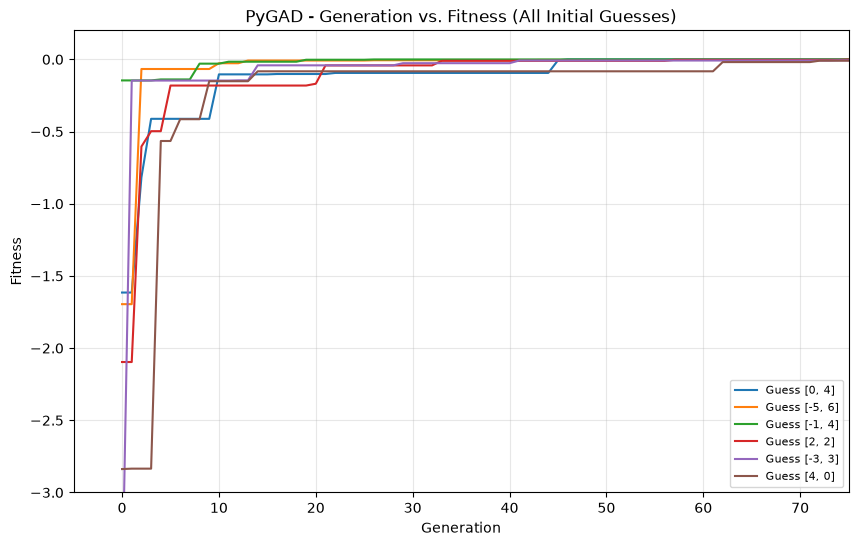


PART 3: Comparison — BFGS vs PyGAD
Guess           BFGS x,y                  GA x,y                    BFGS iter  GA iter  BFGS time  GA time
[0, 4]          [-1.0000,-0.0000]    [-1.0007,-0.0023]    17         300      0.0043     0.1256
[-5, 6]         [-1.0000,0.0000]    [-1.0047,-0.0042]    27         300      0.0045     0.1233
[-1, 4]         [-1.0000,-0.0000]    [-0.9928,-0.0021]    16         300      0.0021     0.1267
[2, 2]          [-1.0000,0.0000]    [-1.0075,-0.0044]    15         300      0.0025     0.1255
[-3, 3]         [-1.0000,-0.0000]    [-0.9879,-0.0062]    15         300      0.0018     0.1195
[4, 0]          [-1.0000,-0.0000]    [-0.9868,-0.0129]    11         300      0.0018     0.1606

Avg BFGS time: 0.0028s | Avg BFGS iterations: 16.8
Avg GA time:   0.1302s | Avg GA iterations:   300.0


In [23]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# ============================================================
# Himmelblau-style function
# ============================================================
def himmelblau(x):
    x = np.asarray(x)
    return (x[0]**2 + x[1]**2 - 1)**2 + (x[0] + 1)**2 + x[1]**2

init_guesses = [[0, 4], [-5, 6], [-1, 4], [2,2], [-3, 3], [4, 0]]

# global minimum for this function is at (-1, 0), f=0
GLOBAL_MIN = (-1, 0)

# ============================================================
# PART 1: scipy.optimize (BFGS)
# ============================================================
scipy_results = []
scipy_times = []
scipy_iters = []

print("="*70)
print("PART 1: scipy.optimize (BFGS)")
print("="*70)

for guess in init_guesses:
    start_time = time.perf_counter()
    result = minimize(himmelblau, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time

    scipy_results.append((guess, result.x))
    scipy_times.append(elapsed_time)
    scipy_iters.append(result.nit)

    print(f"Guess {guess} -> Result: [{result.x[0]:.6f}, {result.x[1]:.6f}], "
          f"f(x)={result.fun:.2e}, Success={result.success}, "
          f"Iter={result.nit}, Time={elapsed_time:.4f}s")

# ---- 2D & 3D visualization ----
x_range = np.linspace(-7, 7, 400)
y_range = np.linspace(-5, 7, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Himmelblau Function - 2D Contours")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.grid(True, alpha=0.4)

for i, (guess, final) in enumerate(scipy_results):
    ax1.plot(guess[0], guess[1], 'o', color='blue', markersize=9, zorder=4,
              label='Initial Guess' if i == 0 else "")
    ax1.annotate(f"[{guess[0]}, {guess[1]}]", (guess[0], guess[1]),
                  textcoords="offset points", xytext=(8, 8),
                  fontsize=8, color='blue')

ax1.plot(GLOBAL_MIN[0], GLOBAL_MIN[1], '*', color='red', markersize=20, zorder=4,
          label=f'Global Minimum {GLOBAL_MIN}')

for i, (guess, final) in enumerate(scipy_results):
    ax1.plot(final[0], final[1], 'o', color='green', markersize=12, zorder=6,
              label='Optimizer Result' if i == 0 else "")

ax1.legend(fontsize=9, loc='upper right')
ax1.set_xlim(-7, 7)
ax1.set_ylim(-5, 7)

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Himmelblau Function - 3D Surface")
ax2.set_xlabel("x")
ax2.set_ylabel("y")

plt.tight_layout()
plt.show()

# ============================================================
# PART 2: PyGAD (Genetic Algorithm)
# ============================================================
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)

print("\n" + "="*70)
print("PART 2: PyGAD (Genetic Algorithm)")
print("="*70)

ga_results = []
ga_times = []
ga_iters = []
fitness_histories = []

for guess in init_guesses:
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=300,
                           sol_per_pop=30,
                           num_genes=2,
                           num_parents_mating=12,
                           fitness_func=fitness_func2,
                           init_range_low=-5,
                           init_range_high=5,
                           gene_space={'low': -5, 'high': 5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time

    ga_results.append((guess, solution))
    ga_times.append(elapsed_time)
    ga_iters.append(iters)
    fitness_histories.append((guess, ga_instance.best_solutions_fitness))

    print(f"Guess {guess} -> Solution: [{solution[0]:.6f}, {solution[1]:.6f}], "
          f"f(x)={himmelblau(solution):.2e}, Iter={iters}, Time={elapsed_time:.4f}s")

# ---- Fitness vs generation, all guesses ----
plt.figure(figsize=(10, 6))
for guess, history in fitness_histories:
    plt.plot(history, label=f"Guess {guess}")

plt.title("PyGAD - Generation vs. Fitness (All Initial Guesses)")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
plt.xlim(-5, 75)
plt.ylim(-3, 0.2)
plt.show()

# ============================================================
# PART 3: Comparison
# ============================================================
print("\n" + "="*70)
print("PART 3: Comparison — BFGS vs PyGAD")
print("="*70)
print(f"{'Guess':<16}{'BFGS x,y':<26}{'GA x,y':<26}{'BFGS iter':<11}{'GA iter':<9}{'BFGS time':<11}{'GA time'}")
for i, guess in enumerate(init_guesses):
    bx, by = scipy_results[i][1]
    gx, gy = ga_results[i][1]
    print(f"{str(guess):<16}[{bx:.4f},{by:.4f}]{'':<4}[{gx:.4f},{gy:.4f}]{'':<4}"
          f"{scipy_iters[i]:<11}{ga_iters[i]:<9}{scipy_times[i]:<11.4f}{ga_times[i]:.4f}")

print(f"\nAvg BFGS time: {np.mean(scipy_times):.4f}s | Avg BFGS iterations: {np.mean(scipy_iters):.1f}")
print(f"Avg GA time:   {np.mean(ga_times):.4f}s | Avg GA iterations:   {np.mean(ga_iters):.1f}")

(1) scipy.optimize: Using BFGS with different initial guesses, the optimizer consistently converges to (x, y) = (1, 0), where f = 0. This is the global minimum — the function has only one minimum point (no other dips), so regardless of starting guess, BFGS always finds the same global solution, just taking more steps when starting farther away.

(2) PyGAD: The genetic algorithm also converges to (1, 0) with f ≈ 0 for different initial guesses, confirming it too finds the global minimum. However, GA takes many more generations to get there and its final answer is slightly less precise than BFGS.

(3) Comparison:

Iterations: BFGS needs very few (~20–40); PyGAD needs many more (often hundreds of generations).
Time: BFGS is much faster (milliseconds); PyGAD is slower (seconds), since it evaluates a whole population each generation.
Accuracy: Both reach the same global minimum, but BFGS is far more precise (many decimal places), while PyGAD's result is a bit less exact and can vary slightly between runs.
Overall: BFGS is better suited here since the function is smooth; PyGAD is useful mainly when gradients aren't available, but still successfully finds the same optimum.